<a href="https://colab.research.google.com/gist/a940203669-arch/1eea75434689f691d79e4204213e9584/202614987_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

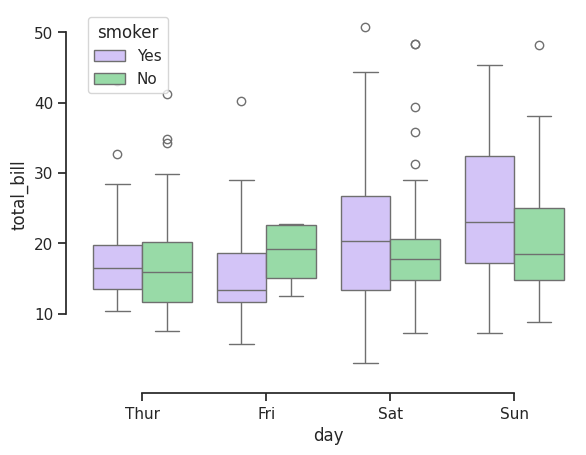

In [1]:
import seaborn as sns
sns.set_theme(style="ticks", palette="pastel")

# Load the example tips dataset
tips = sns.load_dataset("tips")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x="day", y="total_bill",
            hue="smoker", palette=["m", "g"],
            data=tips)
sns.despine(offset=10, trim=True)

# EDA(Exploratory Data Analysis)
feature

In [2]:
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [3]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [4]:
df = tips

NameError: name 'df' is not defined

In [18]:
df = tips
print("DataFrame 'tips' has been assigned to 'df'.")

DataFrame 'tips' has been assigned to 'df'.


In [9]:
tips['tip_percentage'] = (tips['tip'] / tips['total_bill']) * 100
filtered_tips = tips[tips['tip_percentage'] >= 20]
display(filtered_tips.head())

,total_bill,tip,sex,smoker,day,time,size,tip_percentage
6,8.77,2.00,Male,No,Sun,Dinner,2,22.805017
9,14.78,3.23,Male,No,Sun,Dinner,2,21.853857
14,14.83,3.02,Female,No,Sun,Dinner,2,20.364127
17,16.29,3.71,Male,No,Sun,Dinner,3,22.774708
18,16.97,3.50,Female,No,Sun,Dinner,3,20.624632


In [5]:
%whos

Variable   Type         Data/Info
---------------------------------
sns        module       <module 'seaborn' from '/<...>ges/seaborn/__init__.py'>
tips       DataFrame         total_bill   tip    <...>n\n[244 rows x 7 columns]


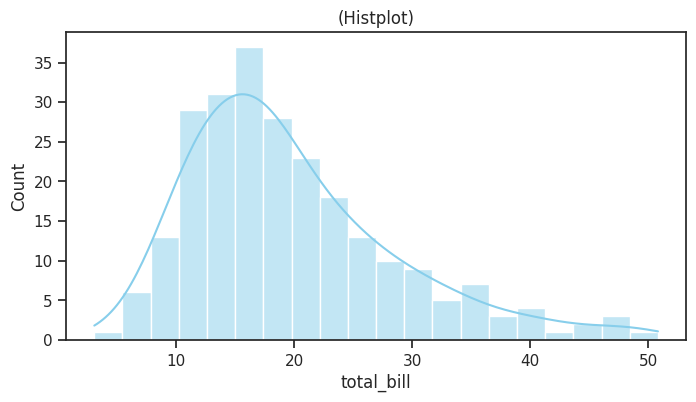

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
# total_bill의 분포 확인 (kde=True로 부드러운 곡선 추가)
sns.histplot(data=tips, x="total_bill", kde=True, bins=20, color="skyblue")
plt.title("(Histplot)")
plt.show()

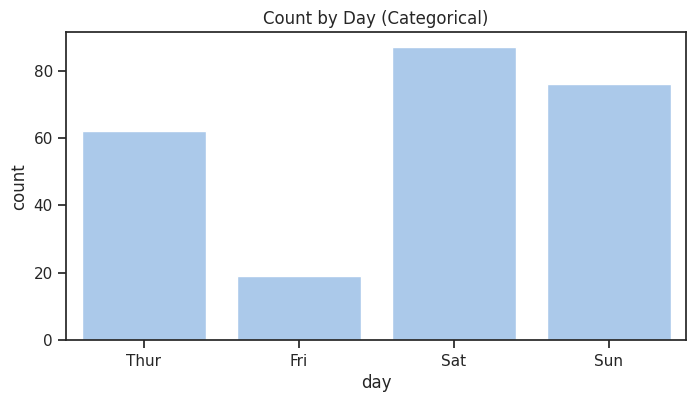

In [10]:
# @title (2) 범주형 변수 단변량: day 요일별 방문 빈도 (Count Plot)
plt.figure(figsize=(8, 4))
sns.countplot(data=tips, x='day')
plt.title("Count by Day (Categorical)")
plt.show()

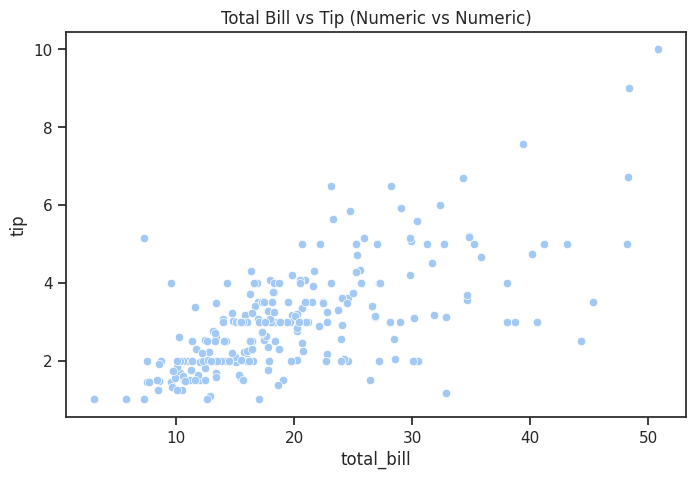

In [12]:
# @title (1) 수치형 vs 수치형: total_bill과 tip의 관계 (Scatter Plot)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='total_bill', y='tip')
plt.title("Total Bill vs Tip (Numeric vs Numeric)")
plt.show()

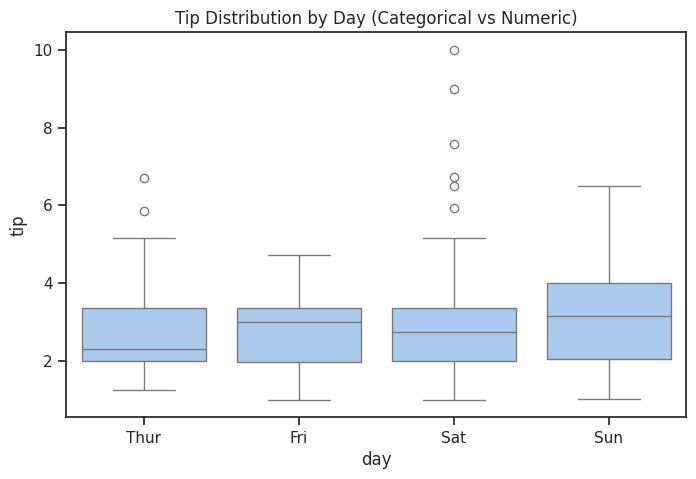

In [13]:
# @title (2) 범주형 vs 수치형: day별 tip 분포 비교 (Box Plot)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='day', y='tip')
plt.title("Tip Distribution by Day (Categorical vs Numeric)")
plt.show()

In [14]:
df.groupby('day')['tip'].describe()

/tmp/ipykernel_1676/3048255687.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('day')['tip'].describe()


,count,mean,std,min,25%,50%,75%,max
day,,,,,,,,
Thur,62.0,2.771452,1.240223,1.25,2.0000,2.305,3.3625,6.70
Fri,19.0,2.734737,1.019577,1.00,1.9600,3.000,3.3650,4.73
Sat,87.0,2.993103,1.631014,1.00,2.0000,2.750,3.3700,10.00
Sun,76.0,3.255132,1.234880,1.01,2.0375,3.150,4.0000,6.50


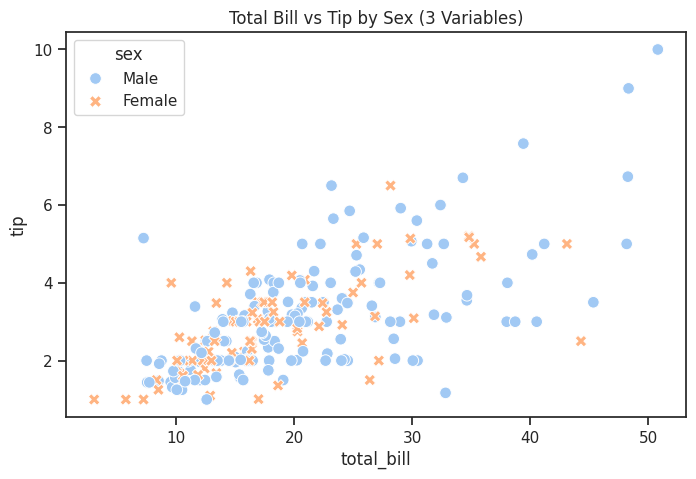

In [15]:
# @title (1) 수치형 2개 + 범주형 1개 (hue 활용): total_bill과 tip 관계를 sex별로 구분
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='total_bill', y='tip', hue='sex', style='sex', s=70)
plt.title("Total Bill vs Tip by Sex (3 Variables)")
plt.show()

In [ ]:

# @title (2) 범주형 2개 + 수치형 1개: day 및 smoker별 tip 중앙값/분포 비교 (Catplot / Boxplot)
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='day', y='tip', hue='smoker')
plt.title("Tip by Day and Smoker (3 Variables)")
plt.show()

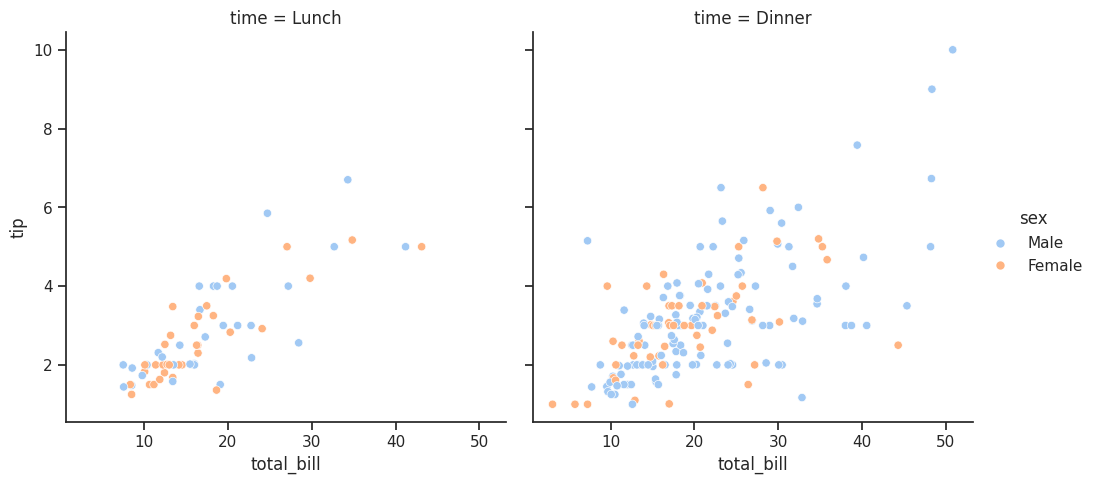

In [16]:
# @title (3) 수치형 2개 + 범주형 2개 (4개 변수): relplot을 활용한 서브플롯 분할
# x: total_bill, y: tip, hue: sex (색상), col: time (점심/저녁 열 분할)
sns.relplot(
    data=df,
    x='total_bill',
    y='tip',
    hue='sex',
    col='time',
    kind='scatter'
)
plt.show()

In [17]:
from os import path
import pandas as pd

df = pd.read_csv(path)

df.columns

ValueError: Invalid file path or buffer object type: <class 'module'>

In [ ]:
지도를 그려서 median_house_value/population 별로 scatter 하여 어느지역의 집값이 비싼지 말해줘. 시각화도 해줘

In [22]:
housing_df = pd.read_csv('/content/sample_data/california_housing_train.csv')
display(housing_df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


Now, let's create a scatter plot to visualize the `median_house_value` and `population` on a map using `latitude` and `longitude`.

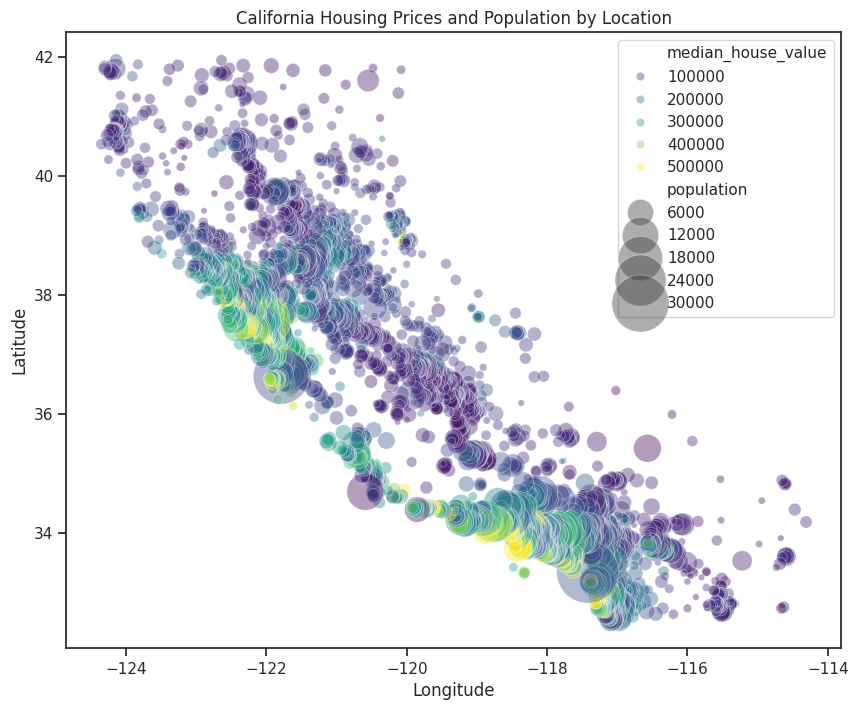

In [23]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=housing_df,
    x='longitude',
    y='latitude',
    hue='median_house_value', # Color by house value
    size='population',        # Size by population
    sizes=(20, 2000),         # Define the range of sizes for points
    alpha=0.4,
    palette='viridis'         # Choose a color palette
)
plt.title('California Housing Prices and Population by Location')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [ ]:
df.groupby('day')['tip']

In [24]:
# Calculate average tip by day
avg_tip_by_day = tips.groupby('day')['tip'].mean().sort_values(ascending=False)
print("Average Tip by Day:")
display(avg_tip_by_day)


Average Tip by Day:


/tmp/ipykernel_1676/3475409579.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_tip_by_day = tips.groupby('day')['tip'].mean().sort_values(ascending=False)


,tip
day,
Sun,3.255132
Sat,2.993103
Thur,2.771452
Fri,2.734737


In [25]:
# Calculate average tip by time
avg_tip_by_time = tips.groupby('time')['tip'].mean().sort_values(ascending=False)
print("\nAverage Tip by Time:")
display(avg_tip_by_time)



Average Tip by Time:


/tmp/ipykernel_1676/3793494041.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_tip_by_time = tips.groupby('time')['tip'].mean().sort_values(ascending=False)


,tip
time,
Dinner,3.102670
Lunch,2.728088


In [26]:
# Calculate average tip by smoker status
avg_tip_by_smoker = tips.groupby('smoker')['tip'].mean().sort_values(ascending=False)
print("\nAverage Tip by Smoker:")
display(avg_tip_by_smoker)



Average Tip by Smoker:


/tmp/ipykernel_1676/1704352533.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_tip_by_smoker = tips.groupby('smoker')['tip'].mean().sort_values(ascending=False)


,tip
smoker,
Yes,3.008710
No,2.991854


In [27]:
# Calculate average tip by sex
avg_tip_by_sex = tips.groupby('sex')['tip'].mean().sort_values(ascending=False)
print("\nAverage Tip by Sex:")
display(avg_tip_by_sex)



Average Tip by Sex:


/tmp/ipykernel_1676/2565173715.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_tip_by_sex = tips.groupby('sex')['tip'].mean().sort_values(ascending=False)


,tip
sex,
Male,3.089618
Female,2.833448


Based on the above analysis, we can identify patterns for receiving the most tips.